In [1]:
import os, json, glob, random, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

random.seed(42)

# ---- EDIT THESE IF NEEDED ----
DATA_DIR   = Path('35_38_all_class')          # where your images + json labels live
WORK_DIR   = Path('/media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects')                # RF-DETR-formatted dataset gets built here
OUTPUT_DIR = Path('rfdetr_runs')  # training outputs (checkpoints, logs)
EPOCHS           = 100
BATCH_SIZE       = 4     # T4-friendly; raise + lower grad_accum_steps on a bigger GPU (e.g. A100: 16 / 1)
GRAD_ACCUM_STEPS = 4     # batch_size * grad_accum_steps ~= 16 is the recommended effective batch size
LR               = 1e-4
MODEL_SIZE       = '2xlarge'   # one of: nano, small, medium, large, xlarge, 2xlarge
# --------------------------------

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
WORK_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
def find_image_json_pairs(data_dir):
    pairs = []
    for img_path in data_dir.rglob('*'):
        if img_path.suffix.lower() in IMAGE_EXTS:
            json_path = img_path.with_suffix('.json')
            if json_path.exists():
                pairs.append((img_path, json_path))
    return pairs

pairs = find_image_json_pairs(DATA_DIR)
print(f"Found {len(pairs)} image/label pairs in {DATA_DIR}")

if len(pairs) == 0:
    raise FileNotFoundError(
        f"No image+json pairs found under {DATA_DIR}. "
        "Check that each image has a same-named .json file next to it."
    )

class_set = set()
skipped_json = 0
for _, json_path in pairs:
    try:
        with open(json_path, 'r') as f:
            data = json.load(f)
        for shape in data.get('shapes', []):
            class_set.add(shape['label'])
    except Exception:
        skipped_json += 1

classes = sorted(class_set)
class_to_id = {c: i for i, c in enumerate(classes)}

print(f"Detected {len(classes)} classes: {classes}")
if skipped_json:
    print(f"Warning: {skipped_json} json files could not be parsed and were skipped.")

Found 3176 image/label pairs in 35_38_all_class
Detected 9 classes: ['albag', 'gloved', 'masked', 'pcs', 'person', 'tray', 'tray_red', 'ungloved', 'unmasked']


In [3]:
def polygon_to_bbox(points):
    """Works for both 'rectangle' (2 points) and 'polygon' (N points) shapes."""
    xs = [p[0] for p in points]
    ys = [p[1] for p in points]
    return min(xs), min(ys), max(xs), max(ys)

def get_image_size(json_data, img_path):
    w = json_data.get('imageWidth')
    h = json_data.get('imageHeight')
    if not w or not h:
        with Image.open(img_path) as im:
            w, h = im.size
    return w, h

def labelme_to_yolo_lines(json_path, img_path, class_to_id):
    with open(json_path, 'r') as f:
        data = json.load(f)
    img_w, img_h = get_image_size(data, img_path)

    lines = []
    for shape in data.get('shapes', []):
        label = shape.get('label')
        if label not in class_to_id:
            continue
        cls_id = class_to_id[label]
        x_min, y_min, x_max, y_max = polygon_to_bbox(shape['points'])

        x_min, x_max = max(0, x_min), min(img_w, x_max)
        y_min, y_max = max(0, y_min), min(img_h, y_max)
        bw, bh = x_max - x_min, y_max - y_min
        if bw <= 0 or bh <= 0:
            continue

        x_center = (x_min + bw / 2) / img_w
        y_center = (y_min + bh / 2) / img_h
        w_norm = bw / img_w
        h_norm = bh / img_h
        lines.append(f"{cls_id} {x_center:.6f} {y_center:.6f} {w_norm:.6f} {h_norm:.6f}")
    return lines

In [4]:
random.shuffle(pairs)
split_idx = int(0.8 * len(pairs))
train_pairs, valid_pairs = pairs[:split_idx], pairs[split_idx:]

for split, split_pairs in [('train', train_pairs), ('valid', valid_pairs)]:
    (WORK_DIR / split / 'images').mkdir(parents=True, exist_ok=True)
    (WORK_DIR / split / 'labels').mkdir(parents=True, exist_ok=True)

    for img_path, json_path in split_pairs:
        lines = labelme_to_yolo_lines(json_path, img_path, class_to_id)

        dst_img = WORK_DIR / split / 'images' / img_path.name
        shutil.copy(img_path, dst_img)

        dst_label = WORK_DIR / split / 'labels' / (img_path.stem + '.txt')
        with open(dst_label, 'w') as f:
            f.write('\n'.join(lines))

print(f"Train: {len(train_pairs)} images | Valid: {len(valid_pairs)} images")

yaml_lines = [
    "names:",
] + [f"  - {c}" for c in classes] + [
    "",
    f"nc: {len(classes)}",
    "",
    "train: train/images",
    "val: valid/images",
]

yaml_path = WORK_DIR / 'data.yaml'
with open(yaml_path, 'w') as f:
    f.write('\n'.join(yaml_lines))

print("\n" + '\n'.join(yaml_lines))

Train: 2540 images | Valid: 636 images

names:
  - albag
  - gloved
  - masked
  - pcs
  - person
  - tray
  - tray_red
  - ungloved
  - unmasked

nc: 9

train: train/images
val: valid/images


In [5]:
def show_examples_per_class(pairs, classes, n_examples=5):
    for cls in classes:
        matching = []
        for img_path, json_path in pairs:
            with open(json_path) as f:
                data = json.load(f)
            labels_here = {s.get('label') for s in data.get('shapes', [])}
            if cls in labels_here:
                matching.append((img_path, json_path))

        if not matching:
            print(f"No images found for class '{cls}', skipping.")
            continue

        sample = random.sample(matching, min(n_examples, len(matching)))
        fig, axes = plt.subplots(1, len(sample), figsize=(4 * len(sample), 4))
        if len(sample) == 1:
            axes = [axes]
        fig.suptitle(f"Label: {cls}  ({len(matching)} images total)", fontsize=14)

        for ax, (img_path, json_path) in zip(axes, sample):
            img = Image.open(img_path).convert('RGB')
            ax.imshow(img)
            with open(json_path) as f:
                data = json.load(f)
            for shape in data.get('shapes', []):
                if shape.get('label') != cls:
                    continue
                x_min, y_min, x_max, y_max = polygon_to_bbox(shape['points'])
                rect = patches.Rectangle(
                    (x_min, y_min), x_max - x_min, y_max - y_min,
                    linewidth=2, edgecolor='lime', facecolor='none'
                )
                ax.add_patch(rect)
            ax.axis('off')

        plt.tight_layout()
        plt.show()

#show_examples_per_class(pairs, classes, n_examples=5)

In [ ]:
%load_ext tensorboard
%tensorboard --logdir $OUTPUT_DIR

In [7]:
EPOCHS           = 100
BATCH_SIZE       = 6     
GRAD_ACCUM_STEPS = 4     # batch_size * grad_accum_steps ~= 16 is the recommended effective batch size
LR               = 1e-4
MODEL_SIZE       = '2xlarge'   # one of: nano, small, medium, large, xlarge, 2xlarge

In [ ]:
# ─────────────────────────────────────────────────────────────
#  1. TRAIN
# ─────────────────────────────────────────────────────────────
from rfdetr import RFDETRNano, RFDETRSmall, RFDETRMedium, RFDETRLarge

MODEL_CLASSES = {
    'nano': RFDETRNano,
    'small': RFDETRSmall,
    'medium': RFDETRMedium,
    'large': RFDETRLarge,
}

# xlarge / 2xlarge live behind the 'plus' extra (pip install "rfdetr[plus]").
# Importing them without that extra installed raises ImportError even if you
# never select them, so only import when actually needed.
if MODEL_SIZE in ('xlarge', '2xlarge'):
    from rfdetr import RFDETRXLarge, RFDETR2XLarge
    MODEL_CLASSES['xlarge'] = RFDETRXLarge
    MODEL_CLASSES['2xlarge'] = RFDETR2XLarge

model = MODEL_CLASSES[MODEL_SIZE]()

#train_results = model.train(
#    dataset_dir=str(WORK_DIR),
#    epochs=EPOCHS,
#    batch_size=BATCH_SIZE,
#    grad_accum_steps=GRAD_ACCUM_STEPS,
#    lr=LR,
#    output_dir=str(OUTPUT_DIR),
#    tensorboard=True,              # logs training/val metrics for TensorBoard
#    early_stopping=True,           # required — patience does nothing without this
#    early_stopping_patience=50,    # stop if val mAP doesn't improve for 30 epochs
#)
#
#best_weights = Path(OUTPUT_DIR) / "checkpoint_best_total.pth"
#print(f"\nTraining complete. Best weights: {best_weights}\n")

In [9]:
from rfdetr import RFDETRNano, RFDETRSmall, RFDETRMedium, RFDETRLarge
MODEL_CLASSES = {
    'nano': RFDETRNano,
    'small': RFDETRSmall,
    'medium': RFDETRMedium,
    'large': RFDETRLarge,
}

if MODEL_SIZE in ('xlarge', '2xlarge'):
    from rfdetr import RFDETRXLarge, RFDETR2XLarge
    MODEL_CLASSES['xlarge'] = RFDETRXLarge
    MODEL_CLASSES['2xlarge'] = RFDETR2XLarge

model = MODEL_CLASSES[MODEL_SIZE]()

train_results = model.train(
    dataset_dir=str(WORK_DIR),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    grad_accum_steps=GRAD_ACCUM_STEPS,
    lr=LR,
    output_dir=str(OUTPUT_DIR),
    tensorboard=True,
    early_stopping=True,
    early_stopping_patience=40,
    checkpoint_interval=50,   # optional: also keep a snapshot every single epoch
)

last_weights = Path(OUTPUT_DIR) / "last.ckpt"
best_weights = Path(OUTPUT_DIR) / "checkpoint_best_total.pth"

print(f"\nTraining complete.")
print(f"Last checkpoint: {last_weights}")
print(f"Best weights:    {best_weights}\n")

/home/avidmech/miniconda3/envs/glm10b-ft/lib/python3.10/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (7.6.0)/charset_normalizer (3.4.9) doesn't match a supported version!
  warnings.warn(


[2026-09-02 14:12:44] [INFO] rf-detr - File /home/avidmech/.roboflow/models/rf-detr-xxlarge.pth already exists with correct MD5 hash.


[2026-09-02 14:12:44] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-02 14:12:44] [WARNING] rf-detr - Using patch size 20 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-09-02 14:12:45] [INFO] rf-detr - File /home/avidmech/.roboflow/models/rf-detr-xxlarge.pth already exists with correct MD5 hash.


[2026-09-02 14:12:45] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 365. Using checkpoint class count (90). Pass num_classes=90 to suppress this warning.
[2026-09-02 14:12:46] [WARNING] rf-detr - Dataset '/media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects' has 9 classes but model was initialized with num_classes=90. Using the model's configured value (90). If this is unintentional, reinitialize the model with num_classes=9.
[2026-09-02 14:12:46] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-02 14:12:46] [WARNING] rf-detr - Using patch size 20 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-09-02 14:12:47] [INFO] rf-detr - File /home/avidmech/.roboflow/models/rf-detr-xxlarge.pth already exists with correct MD5 hash.


... (135 outputs left out)

[2026-09-02 23:46:33] [INFO] rf-detr - Best EMA mAP improved to 0.8323 (epoch 98)


[2026-09-02 23:52:32] [INFO] rf-detr - Best EMA mAP improved to 0.8323 (epoch 99)


`Trainer.fit` stopped: `max_epochs=100` reached.


[2026-09-02 23:52:54] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.8199, ema=0.8323)

Training complete.
Last checkpoint: rfdetr_runs/last.ckpt
Best weights:    rfdetr_runs/checkpoint_best_total.pth



[2026-09-05 09:32:28] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-05 09:32:28] [WARNING] rf-detr - Using patch size 20 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-05 09:32:28] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 365. Using checkpoint class count (90). Pass num_classes=90 to suppress this warning.
[2026-09-05 09:32:29] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


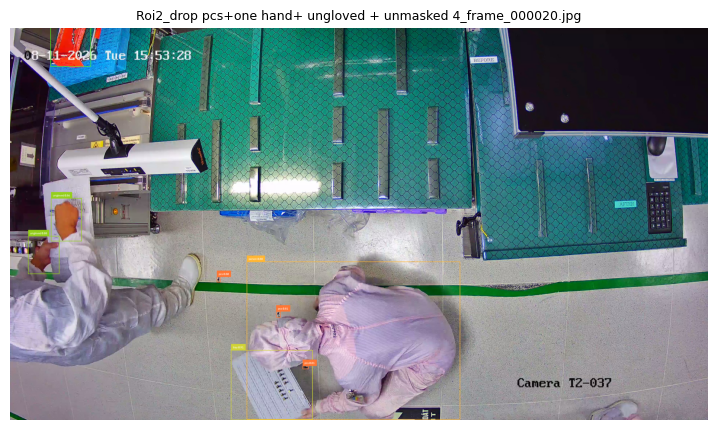

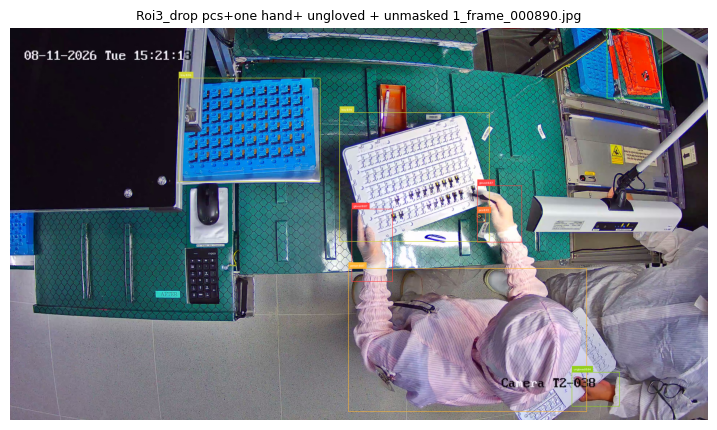

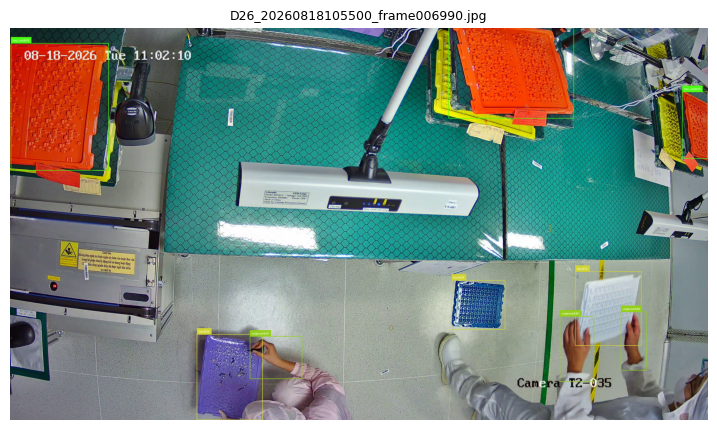

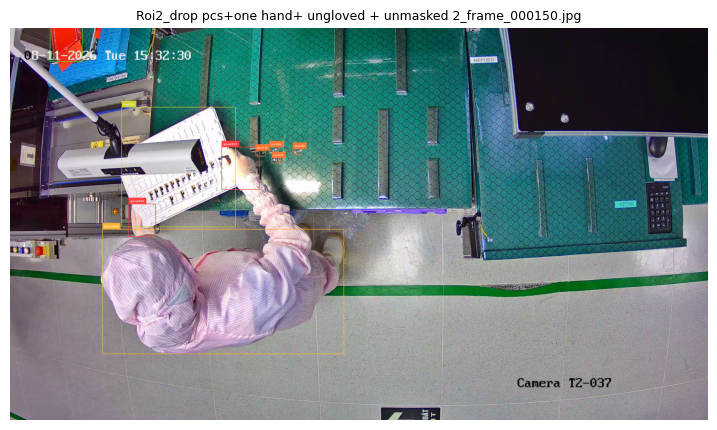

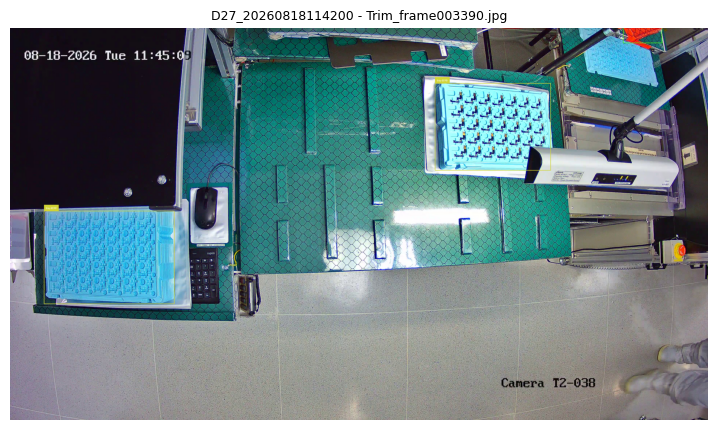

In [15]:
# ─────────────────────────────────────────────────────────────
# LIVE METRICS — plot training curves from results.csv
# ─────────────────────────────────────────────────────────────
import pandas as pd
from IPython.display import clear_output

def plot_live_metrics(trainer):
    csv_path = trainer.save_dir / 'results.csv'
    if not csv_path.exists():
        return
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    clear_output(wait=True)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    if 'train/box_loss' in df.columns:
        axes[0].plot(df['epoch'], df['train/box_loss'], label='train box loss')
    if 'val/box_loss' in df.columns:
        axes[0].plot(df['epoch'], df['val/box_loss'], label='val box loss')
    axes[0].set_title('Box Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()

    map_cols = [c for c in df.columns if 'mAP' in c]
    for c in map_cols:
        axes[1].plot(df['epoch'], df[c], label=c)
    axes[1].set_title('mAP'); axes[1].set_xlabel('epoch'); axes[1].legend()

    pr_cols = [c for c in df.columns if 'precision' in c.lower() or 'recall' in c.lower()]
    for c in pr_cols:
        axes[2].plot(df['epoch'], df[c], label=c)
    axes[2].set_title('Precision / Recall'); axes[2].set_xlabel('epoch'); axes[2].legend()

    plt.tight_layout()
    plt.show()


# ───────────────────────────────────────────────────────────── 
# 3. SAMPLE PREDICTIONS — visualize model output on random val images 
# ───────────────────────────────────────────────────────────── 
import random
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import supervision as sv

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Reload the trained model from its best checkpoint
best_model = MODEL_CLASSES[MODEL_SIZE](pretrain_weights=str(best_weights))

# RF-DETR expects COCO-style folders (train/valid/test), not YOLO's images/val —
# adjust this path to match your actual dataset_dir layout
val_img_dir = WORK_DIR / 'valid' / 'images'
val_images = [p for p in val_img_dir.glob('*') if p.suffix.lower() in IMG_EXTS]

if not val_images:
    print(f"No images found in {val_img_dir}")
else:
    sample_val = random.sample(val_images, min(5, len(val_images)))

    box_annotator = sv.BoxAnnotator()
    label_annotator = sv.LabelAnnotator()

    for img_path in sample_val:
        image = Image.open(img_path).convert("RGB")
        detections = best_model.predict(image, threshold=0.5)

        # detections.data["class_name"] resolves names from your fine-tuned
        # checkpoint's own class map — COCO_CLASSES only works for COCO-pretrained models
        labels = [
            f"{name} {conf:.2f}"
            for name, conf in zip(detections.data["class_name"], detections.confidence)
        ]

        annotated_image = box_annotator.annotate(image.copy(), detections)
        annotated_image = label_annotator.annotate(annotated_image, detections, labels)

        plt.figure(figsize=(9, 9))
        plt.imshow(annotated_image)
        plt.title(img_path.name, fontsize=9)
        plt.axis('off')
        plt.show()

In [ ]:
# ─────────────────────────────────────────────────────────────
#  3. SAMPLE PREDICTIONS — visualize model output on random val images
# ─────────────────────────────────────────────────────────────
import random
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import supervision as sv

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Reload the trained model from its best checkpoint
best_model = MODEL_CLASSES[MODEL_SIZE](pretrain_weights=str(best_weights))

# RF-DETR expects COCO-style folders (train/valid/test), not YOLO's images/val —
# adjust this path to match your actual dataset_dir layout
val_img_dir = WORK_DIR / 'valid'/ 'images'
val_images = [p for p in val_img_dir.glob('*') if p.suffix.lower() in IMG_EXTS]

if not val_images:
    print(f"No images found in {val_img_dir}")
else:
    sample_val = random.sample(val_images, min(5, len(val_images)))

    box_annotator = sv.BoxAnnotator()
    label_annotator = sv.LabelAnnotator()

    for img_path in sample_val:
        image = Image.open(img_path).convert("RGB")
        detections = best_model.predict(image, threshold=0.5)

        # detections.data["class_name"] resolves names from your fine-tuned
        # checkpoint's own class map — COCO_CLASSES only works for COCO-pretrained models
        labels = [
            f"{name} {conf:.2f}"
            for name, conf in zip(detections.data["class_name"], detections.confidence)
        ]

        annotated_image = box_annotator.annotate(image.copy(), detections)
        annotated_image = label_annotator.annotate(annotated_image, detections, labels)

        plt.figure(figsize=(6, 6))
        plt.imshow(annotated_image)
        plt.title(img_path.name, fontsize=9)
        plt.axis('off')
        plt.show()

In [4]:
from pathlib import Path
from rfdetr import RFDETRNano, RFDETRSmall, RFDETRMedium, RFDETRLarge

MODEL_CLASSES = {
    'nano': RFDETRNano,
    'small': RFDETRSmall,
    'medium': RFDETRMedium,
    'large': RFDETRLarge,
}
OUTPUT_DIR = Path('rfdetr_runs')
best_weights = "/media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects/rfdetr_runs/checkpoint_best_total.pth"
MODEL_SIZE       = '2xlarge' 
if MODEL_SIZE in ('xlarge', '2xlarge'):
    from rfdetr import RFDETRXLarge, RFDETR2XLarge
    MODEL_CLASSES['xlarge'] = RFDETRXLarge
    MODEL_CLASSES['2xlarge'] = RFDETR2XLarge

In [6]:
# ─────────────────────────────────────────────────────────────
# 4. VIDEO INFERENCE — run the trained model on a video and save
#    an annotated copy, with big/clear boxes+labels, at 30 FPS
# ─────────────────────────────────────────────────────────────
import cv2
import numpy as np
from PIL import Image
from tqdm import tqdm
import supervision as sv

SOURCE_VIDEO_PATH = "/media/avidmech/5f24ef25-197a-42b3-9359-3c9991c059ef/object detetcion_ glove_mask_fallen_objects/rfdetr_runs/done_D28_20260829154004_PCS_Ungloved.mp4"          # <-- set this
TARGET_VIDEO_PATH = "output_detected_done_D28_20260829154004_PCS_Ungloved.mp4"     # <-- set this
CONFIDENCE_THRESHOLD = 0.5
OUTPUT_FPS = 30          # forces the output container's fps metadata to 30
MAX_FRAMES = None        # e.g. 30 to only process the first 30 frames for a quick test

# Reload the trained model from its best checkpoint (skip this line if
# `best_model` is already in memory from the previous cell)
best_model = MODEL_CLASSES[MODEL_SIZE](pretrain_weights=str(best_weights))

# Big, clear annotation style — bump these further if it's still too small
# for your resolution (e.g. text_scale=1.6, thickness=6 for 4K video)
box_annotator = sv.BoxAnnotator(thickness=4)
label_annotator = sv.LabelAnnotator(
    text_scale=1.2,
    text_thickness=2,
    text_padding=10,
)

source_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)
target_info = sv.VideoInfo(
    width=source_info.width,
    height=source_info.height,
    fps=OUTPUT_FPS,
    total_frames=source_info.total_frames,
)

frame_generator = sv.get_video_frames_generator(
    source_path=SOURCE_VIDEO_PATH,
    end=MAX_FRAMES,
)
total_to_process = MAX_FRAMES or source_info.total_frames

with sv.VideoSink(target_path=TARGET_VIDEO_PATH, video_info=target_info) as sink:
    for frame in tqdm(frame_generator, total=total_to_process, desc="Annotating video"):
        # supervision hands the callback BGR numpy frames (OpenCV convention);
        # RF-DETR's .predict() expects a PIL RGB image, same as your image cell
        image = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        detections = best_model.predict(image, threshold=CONFIDENCE_THRESHOLD)

        labels = [
            f"{name} {conf:.2f}"
            for name, conf in zip(detections.data["class_name"], detections.confidence)
        ]

        annotated = box_annotator.annotate(frame.copy(), detections)
        annotated = label_annotator.annotate(annotated, detections, labels)
        sink.write_frame(annotated)

print(f"Done — annotated video saved to {TARGET_VIDEO_PATH}")

[2026-09-05 10:29:32] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-05 10:29:32] [WARNING] rf-detr - Using patch size 20 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-05 10:29:33] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 365. Using checkpoint class count (90). Pass num_classes=90 to suppress this warning.
Annotating video: 100%|██████████| 6361/6361 [17:59<00:00,  5.89it/s]

Done — annotated video saved to output_detected_done_D28_20260829154004_PCS_Ungloved.mp4
